# Stern model vs Kalshi: 799 games

Game 6 suggested our model trusts a lead more than the market does. This notebook checks
that on every eligible game in the tuning period, and asks three questions the quoting rule depends on:

1. **Who is better calibrated, the model or the market?** If the model never beats the
   market, quoting around it loses money.
2. **Where do they disagree?** By quarter and by how lopsided the game is.
3. **What σ is the market acting as if it uses?** Compared with our fitted 19.64.

All data comes from `src/batch_compare.py`, which saves it to
`data/processed/kalshi_vs_model.parquet`. This notebook makes no API calls. The run shown
here is `uv run python src/batch_compare.py --n 803` (the default is a quick 100).

## Setup

In [33]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import batch_compare as bc
import compare_plots as cp  # every chart below

df = bc.load_results()
games = cp.per_game(df)
Q = bc.QUARTER_LABELS

print(f"{len(games)} games, {len(df):,} in-game minutes with a two-sided Kalshi quote")
print(f"{games['date'].min():%Y-%m-%d} to {games['date'].max():%Y-%m-%d}, "
      f"{games.index.str.startswith('004').sum()} playoff games, "
      f"home team won {games['home_won'].mean():.0%}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
799 games, 102,533 in-game minutes with a two-sided Kalshi quote
2025-04-19 to 2026-01-31, 80 playoff games, home team won 56%


**What is in the data.** Games are every Kalshi game in the tuning period (2025 playoffs to
Jan 2026) that matched an NBA game, drawn in a seeded random order (seed 473); Feb-Jun 2026 is held out for testing the market maker. Each
row is one Kalshi minute during the game, with the market mid as P(home wins) and the
score and clock as of the most recent play. Two model versions are scored:

- **model, Elo prior**: starts from our Elo pregame probability (the full pipeline).
- **model, tip-off prior**: starts from Kalshi's own price at tip-off, so model and
  market start equal and every later difference is purely in-game updating.

Two kinds of minutes are left out: ones where the order book was one-sided (a bid of 0
or an ask of 1, which happens once a game is decided), and the final buzzer. Both would
flatter the model, which is certain there while the market is not.

Every average below treats **the game as the unit**: each game's minutes are averaged
first, then games are averaged with equal weight, and ±95% intervals are across games.
Minutes within one game are far from independent, so per-minute intervals would be
much too narrow.

## 1. Who predicts the result better?

Log loss and Brier score of each predictor against the final result, on exactly the same
minutes (lower is better). The `- market` rows are the difference from the market:
negative means the model is better.

In [34]:
scores = pd.concat({metric: bc.score_table(df, metric=metric).set_index("value")[["mean", "ci95"]]
                    for metric in bc.LOSSES}, axis=1)
scores.round(4)

log_loss           brier        
                                  mean    ci95    mean    ci95
value                                                         
market                          0.4926  0.0277  0.1647  0.0111
model, Elo prior                0.5055  0.0266  0.1692  0.0105
model, tip-off prior            0.4930  0.0285  0.1643  0.0111
model, Elo prior - market       0.0128  0.0104  0.0045  0.0043
model, tip-off prior - market   0.0003  0.0037 -0.0004  0.0013

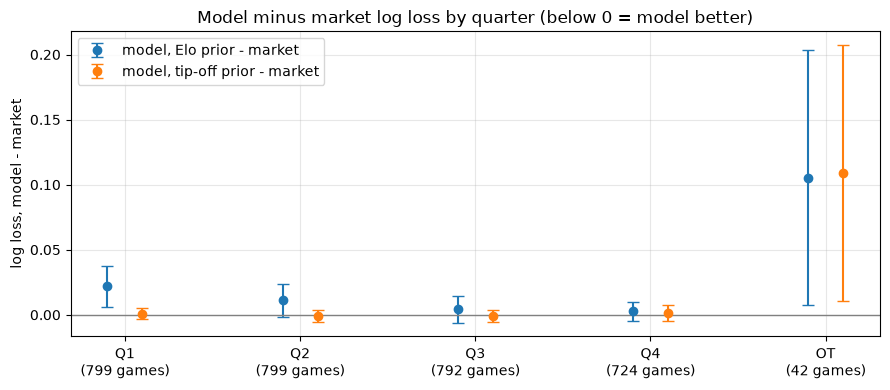

In [35]:
cp.log_loss_by_quarter(df)
plt.show()

## 2. Calibration

When a predictor says 70%, does the home team win about 70% of the time? Minutes are
bucketed by each predictor's own probability; error bars are ±95% across games.

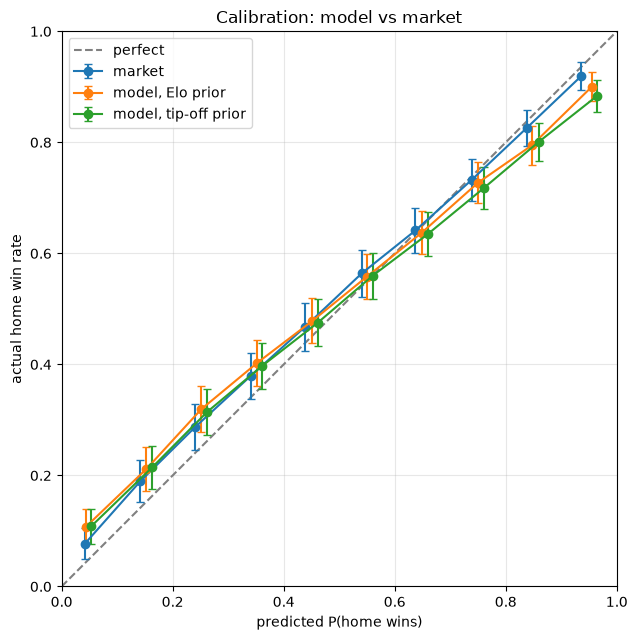

In [36]:
cp.calibration(df)
plt.show()

## 3. Where do they disagree?

**Gap = model - market.** Bucketed by the *market's* probability, not the model's.
Bucketing by the model would show a false tilt: any minute where the model happens to be
high would land in a high bucket, making the model look extreme even if its errors were
pure noise.

If the model trusts leads more than the market, the gap is negative where the market
says the home team is behind (low buckets) and positive where it says ahead.

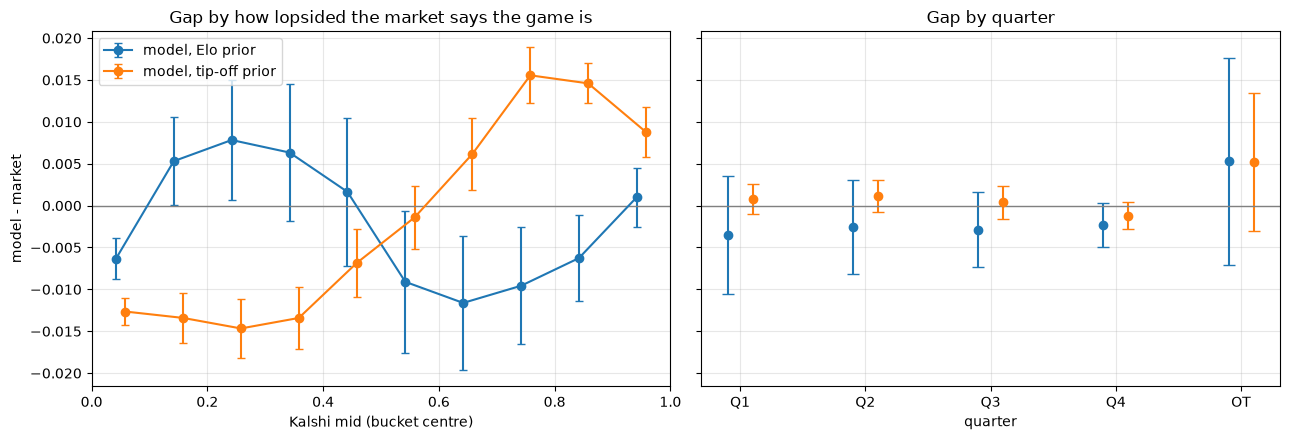

In [37]:
cp.gap(df)
plt.show()

In [38]:
abs_gap = bc.clustered(df, {name: (df[col] - df["mid"]).abs() for name, col in bc.PREDICTORS.items()
                            if name != "market"}, by="quarter")
abs_gap.assign(quarter=abs_gap["group"].map(Q)).pivot(index="quarter", columns="value", values="mean") \
       .reindex(Q.values()).round(3).rename_axis(columns="mean |model - market|")

mean |model - market|,"model, Elo prior","model, tip-off prior"
quarter,,
Q1,0.080,0.027
Q2,0.062,0.026
Q3,0.049,0.026
Q4,0.036,0.028
OT,0.065,0.059


## 4. What σ is the market using?

Using the tip-off prior, so σ is the only thing separating model from market, sweep σ and
measure (left) how far the model sits from the Kalshi mid and (right) how well it
predicts the result. The σ that best matches the market is the market's *implied* σ.

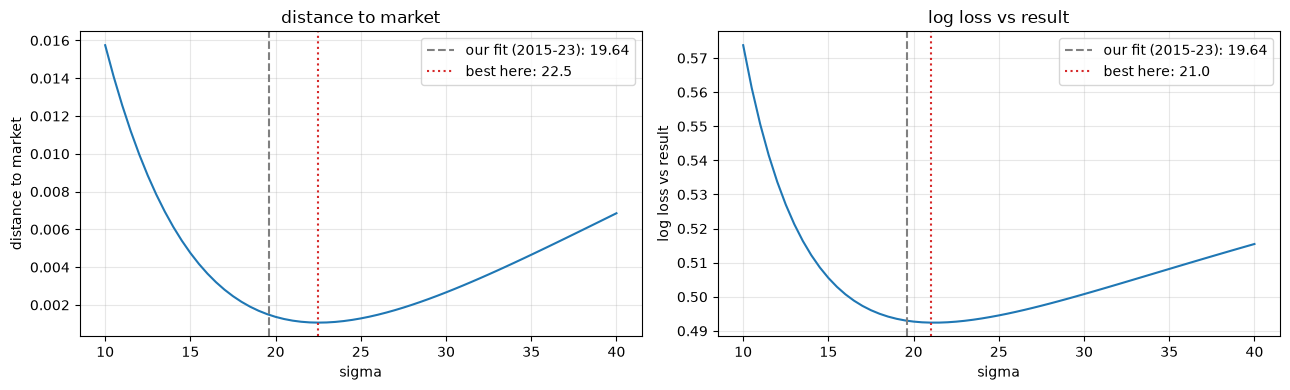

In [39]:
cp.sigma_sweep(df)
plt.show()

In [40]:
by_q = bc.best_sigma(bc.sigma_curve(df, by="quarter"))
by_q.index = by_q.index.map(Q)
by_q.rename_axis(index="quarter", columns="best sigma for")

best sigma for,distance to market,log loss vs result
quarter,,
Q1,26.0,31.0
Q2,23.0,23.0
Q3,22.0,21.5
Q4,21.5,19.5
OT,24.5,33.5


## 5. Elo prior vs Kalshi's tip-off price

How far apart are the two starting points, and which predicts the winner better before
the game starts? One row per game here, so the interval is across the same games.

Elo             log loss +0.6489  ±0.0259
Kalshi tip-off  log loss +0.6224  ±0.0290
Elo - Kalshi    log loss +0.0266  ±0.0169


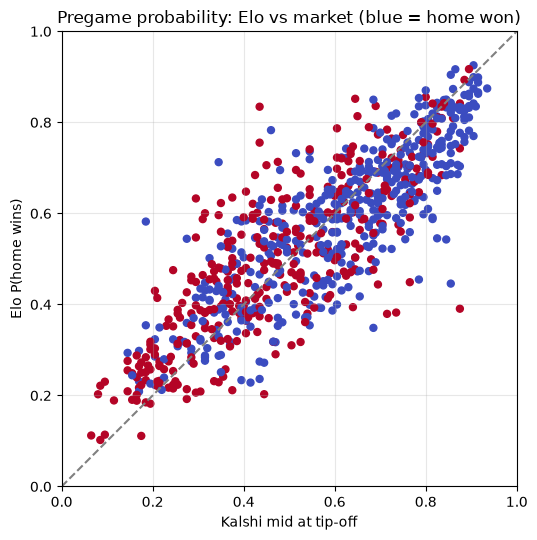

correlation 0.84, mean |Elo - Kalshi| 0.086


In [41]:
pregame = {
    "Elo": bc.log_loss_rows(games["home_won"].to_numpy(), games["prior_elo"].to_numpy()),
    "Kalshi tip-off": bc.log_loss_rows(games["home_won"].to_numpy(), games["prior_tipoff"].to_numpy()),
}
pregame["Elo - Kalshi"] = pregame["Elo"] - pregame["Kalshi tip-off"]
for name, losses in pregame.items():
    print(f"{name:<15} log loss {losses.mean():+.4f}  ±{1.96 * losses.std(ddof=1) / np.sqrt(len(losses)):.4f}")

cp.pregame(df)
plt.show()
print(f"correlation {games['prior_elo'].corr(games['prior_tipoff']):.2f}, "
      f"mean |Elo - Kalshi| {(games['prior_elo'] - games['prior_tipoff']).abs().mean():.3f}")

## 6. Example games

Six games picked at random from the sample, to put pictures behind the averages.

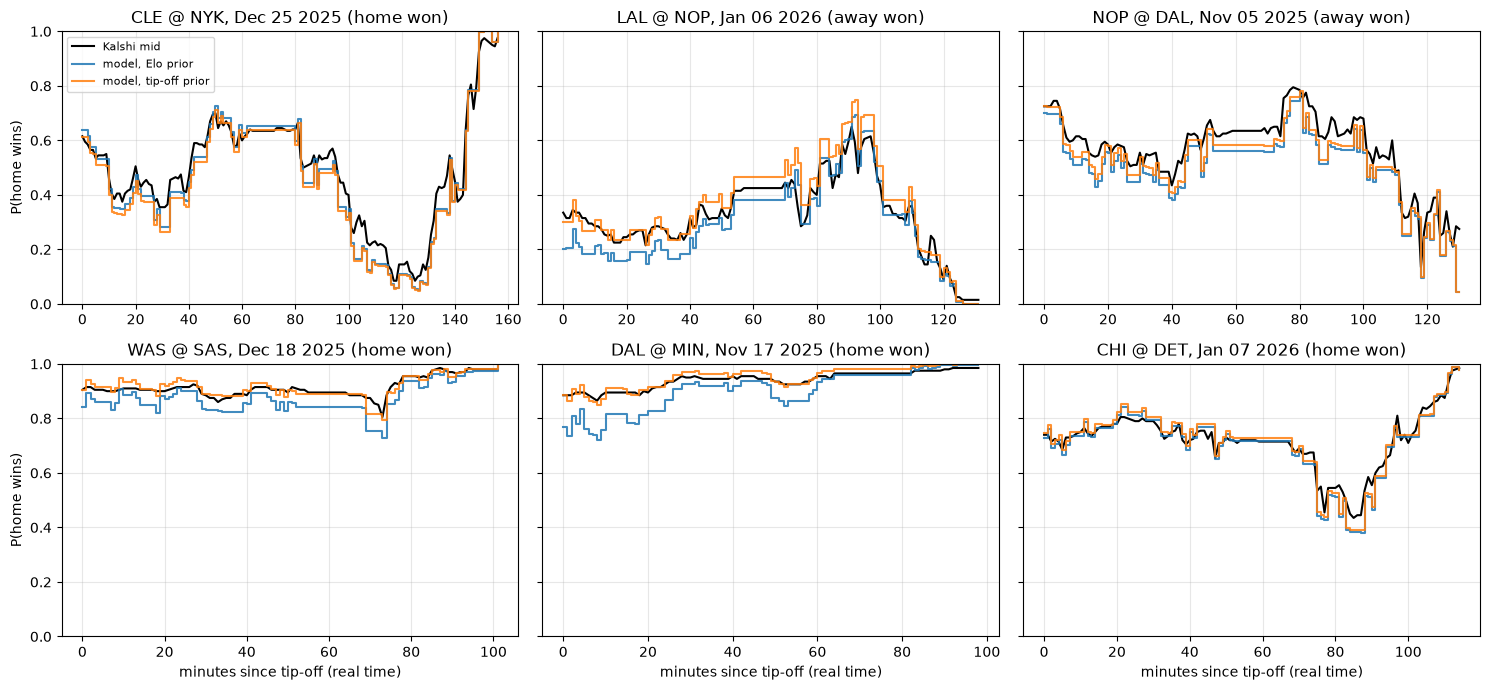

In [42]:
cp.example_games(df)
plt.show()

## 7. How the estimates settle with more games

The headline numbers recomputed on the first 25, 50, 100, ... games of the sample, in the
order the seeded sample draws them (so the 100 point is the 100-game run). Small samples
swing a lot, especially the sigma that best predicts results, because its curve is flat;
the intervals narrow as games are added and the estimates settle. Each run's charts are
also saved under `figures/kalshi_comparison/<games>_games/` so runs can be compared.

In [ ]:
cp.sample_size(df)
plt.show()

## Conclusions

**Data coverage.** 799 of the 803 eligible games are used. The data checks left out four,
all for feed problems rather than anything about the game itself:

| Game | Reason |
|---|---|
| GSW @ OKC, Nov 11 2025 | NBA feed's play timestamps jump back by over 5 minutes |
| DEN @ MIN, Nov 15 2025 | same |
| GSW @ BKN, Dec 29 2025 | NBA feed's game clock runs backwards |
| CLE @ PHI, Jan 16 2026 | no two-sided Kalshi quote before tip-off, so no starting price |

They don't change the results. They are 0.5% of the games, and even if all four had the
largest model-market difference of any game, the headline number in point 1 would move
from +0.0003 to somewhere between -0.0014 and +0.0020, inside its ±0.0037 interval.

**1. The model has no edge over the market.** Started from Kalshi's tip-off price, the
model's log loss is +0.0003 ± 0.0037 relative to the market, and no regulation quarter
differs from zero. The "edge" in the 100-game run (-0.007) was noise: section 7 shows it
shrinking to zero as games are added. Any profit has to come from the spread, not from
predicting winners better than Kalshi.

**2. The Elo prior makes the model worse.** With Elo the model is +0.013 ± 0.010 behind
the market, now clear of zero. The damage is early: +0.022 in Q1 falling to +0.003 in Q4
as the score takes over (8 cents from the market in Q1, 3.6 in Q4). Before tip-off,
Kalshi's price beats Elo by 0.027 ± 0.017 log loss, and the two are 8.6 cents apart on
average.

**3. The model is too extreme; the market is not.** Bucketed by the market's probability,
the tip-off model sits 1.3-1.5 cents below the market when the home team is behind and
about 1.5 cents above when it is ahead (intervals about ±0.3 cents). Calibration says
the market is the one that's right. It stays within its error bars (only the 15% bucket touches the edge), while
the models' 15-35% and 75-85% buckets are 4-6 points too extreme: when the model says
25%, the home team wins about 31%. Home teams won 55.6% against an average tip-off price
of 55.3%, so unlike the 100-game run (62%), luck isn't distorting this. The 5% and 95%
buckets look worse in the chart than they are: each game counts once per bucket, so
games that touch an extreme only briefly get full weight. Weighted by minutes, those
buckets are within 2 points.

**4. σ ≈ 22, not 19.64.** The market acts as if σ = 22.5 (22-22.5 from 50 games on). The
σ that best predicts results is 21.0, but that curve is flat: anything from 19.5 to 22.5
is within 0.0006 log loss. So the results alone can't separate them, and the calibration
in point 3 favours the higher end. By quarter the market's σ falls from 26 in Q1 to 21.5
in Q4: it discounts early leads more than a constant σ does.

**5. Overtime is a weak spot.** In OT the model is 0.11 ± 0.10 behind the market. That is
only 42 games, but worth checking before quoting in overtime.

### What this means for the quoting rule

- **Start from Kalshi's pregame price, not Elo, and use σ ≈ 22.** That removes the two
  biggest sources of model-market disagreement.
- **Spread floor of about 3 cents**, the typical model-market disagreement (2.6-2.8 cents
  per minute). Widen it with `stern.p_volatility` late in close games and in overtime.
- **Speed matters more than prediction.** With no predictive edge, a quote that lags a
  play gets picked off, so the next check decides how far to trust the model.

### Next checks

- **Lead-lag:** does Kalshi move before our play timestamps? This needs Kalshi's
  trade-level data; 1-minute candles are too coarse.
- **Overtime:** check how the model handles the overtime clock.
- **Quoting rule and backtest** against a market maker that follows the mid, then one
  run on the held-out Feb-Jun 2026 games.